# Olist Orders: Data Preparation

## 1. Data cleaning

In [79]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

### 1.1 Load and inspect

In [80]:
orders = pd.read_csv("olist_orders_dataset.csv")
print("*********************************************************************")
print("sape=",orders.shape)
print("*********************************************************************")
print(orders.describe())
print("*********************************************************************")
print(orders.info())
print("*********************************************************************")
orders

*********************************************************************
sape= (99441, 8)
*********************************************************************
                                order_id                       customer_id  \
count                              99441                             99441   
unique                             99441                             99441   
top     66dea50a8b16d9b4dee7af250b4be1a5  edb027a75a1449115f6b43211ae02a24   
freq                                   1                                 1   

       order_status order_purchase_timestamp    order_approved_at  \
count         99441                    99441                99281   
unique            8                    98875                90733   
top       delivered      2018-08-02 12:06:07  2018-02-27 04:31:10   
freq          96478                        3                    9   

       order_delivered_carrier_date order_delivered_customer_date  \
count                         97658  

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00
...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00


### 1.2 Missing values ( NULL )

In [81]:
df=orders
print(df.isnull().values.any() )
print("*********************************************************************")
print(df.isnull().sum())
print("*********************************************************************")
print(df.isnull().sum().sum())
print("*********************************************************************")
print(df.isna().sum())


date_null_cols = ["order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date"]
for col in date_null_cols:
    orders[col] = orders[col].fillna(orders["order_status"])
print(orders[date_null_cols].isna().sum())

True
*********************************************************************
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64
*********************************************************************
4908
*********************************************************************
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64
order_approved_at                0
order_delivered_carrier_date     0
order_delivered_customer_date    0
dtype: int64


### 1.3 Duplicates

In [82]:
print("Rows before:", len(orders))
orders = orders.drop_duplicates()
orders = orders.drop_duplicates(subset="order_id", keep="first")
print("Rows after:", len(orders))

Rows before: 99441
Rows after: 99441


### 1.4 Order status

In [83]:
# Status is a nominal category, so it is kept as clean text (no numeric codes).
orders["order_status"] = orders["order_status"].str.strip().str.lower()
print(orders["order_status"].value_counts())

orders

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00
...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00


## 2. Data transformation

### 2.1 Convert date columns to datetime

In [84]:
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

# Missing dates stay as NaT: they mark stages the order never reached.
print(orders[date_cols].isna().sum())

order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


### 2.1 regular encoding

In [85]:
#normalize the "order_status" column
orders["order_status"] = orders["order_status"].str.strip().str.lower()

status_dict = {}

for status in orders["order_status"]:
    if status in status_dict:
        status_dict[status] += 1
    else:
        status_dict[status] = 1

print(status_dict)
status_map = {
    "created": 0,
    "approved": 1,
    "invoiced": 2,
    "processing": 3,
    "shipped": 4,
    "delivered": 5,
    "unavailable": 6,
    "canceled": 7,
}

orders["order_status"] = orders["order_status"].map(status_map)

print(orders["order_status"].value_counts().sort_index())
orders

{'delivered': 96478, 'invoiced': 314, 'shipped': 1107, 'processing': 301, 'unavailable': 609, 'canceled': 625, 'created': 5, 'approved': 2}
order_status
0        5
1        2
2      314
3      301
4     1107
5    96478
6      609
7      625
Name: count, dtype: int64


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,5,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,5,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,5,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,5,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,5,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26
...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,5,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,5,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,5,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,5,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15


### 2.2 Study period

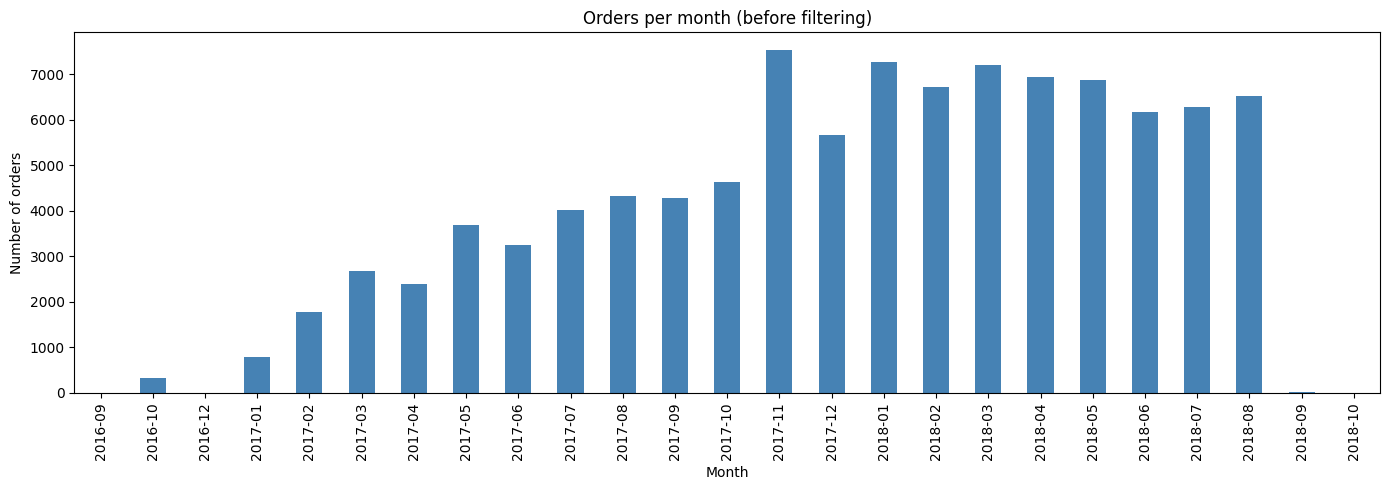

In [86]:
orders["order_purchase_timestamp"].dt.to_period("M").value_counts().sort_index().plot(
    kind="bar", figsize=(14, 5), color="steelblue"
)
plt.title("Orders per month (before filtering)")
plt.xlabel("Month")
plt.ylabel("Number of orders")
plt.tight_layout()
plt.show()

In [87]:
start, end = pd.Timestamp("2016-09-04"), pd.Timestamp("2018-10-17 23:59:59")
rows_before = len(orders)
orders = orders[orders["order_purchase_timestamp"].between(start, end)]
print("Rows removed:", rows_before - len(orders))
print("Purchase range:", orders["order_purchase_timestamp"].min(), "to",
      orders["order_purchase_timestamp"].max())

Rows removed: 0
Purchase range: 2016-09-04 21:15:19 to 2018-10-17 17:30:18


### 2.3 Impossible date sequences

In [88]:
# Flagged, not removed, so they can be reviewed.
checks = {
    "approved_before_purchase": orders["order_approved_at"] < orders["order_purchase_timestamp"],
    "carrier_before_approval": orders["order_delivered_carrier_date"] < orders["order_approved_at"],
    "delivered_before_carrier": orders["order_delivered_customer_date"] < orders["order_delivered_carrier_date"],
}
for name, mask in checks.items():
    orders[f"flag_{name}"] = mask
    print(f"{name}: {mask.sum()}")

flag_cols = [f"flag_{name}" for name in checks]
print("Rows with at least one impossible sequence:", orders[flag_cols].any(axis=1).sum())

orders

approved_before_purchase: 0
carrier_before_approval: 1359
delivered_before_carrier: 23
Rows with at least one impossible sequence: 1382


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,flag_approved_before_purchase,flag_carrier_before_approval,flag_delivered_before_carrier
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,5,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,False,False
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,5,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False,False,False
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,5,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,False,False,False
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,5,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,False,False,False
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,5,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,5,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,False,False,False
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,5,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,False,False,False
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,5,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,False,False,False
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,5,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,False,False,False


## 3. Feature engineering

### 3.1 Time features (in days)

In [89]:
orders["approval_days"] = (
    orders["order_approved_at"] - orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

orders["carrier_days"] = (
    orders["order_delivered_carrier_date"] - orders["order_approved_at"]
).dt.total_seconds() / 86400

orders["delivery_duration_days"] = (
    orders["order_delivered_customer_date"] - orders["order_delivered_carrier_date"]
).dt.total_seconds() / 86400

orders["delivery_total_duration_days"] = (
    orders["order_delivered_customer_date"] - orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

feature_cols = ["approval_days", "carrier_days", "delivery_duration_days", "delivery_total_duration_days"]

undelivered = ~orders["order_status"].isin([5, "delivered"])
orders.loc[undelivered, feature_cols] = -1
print("Undelivered orders set to -1:", undelivered.sum())


# Analysis set: delivered orders with complete timings and no negative duration.
delivered = orders[orders["order_status"] == "delivered"].dropna(
    subset=["delivery_duration_days", "approval_days", "carrier_days"]
)
delivered = delivered[delivered["delivery_duration_days"] >= 0].copy()
print("Delivered orders in analysis set:", len(delivered))
print(delivered[["delivery_duration_days", "approval_days", "carrier_days"]].describe())

orders

Undelivered orders set to -1: 2963
Delivered orders in analysis set: 0
       delivery_duration_days  approval_days  carrier_days
count                     0.0            0.0           0.0
mean                      NaN            NaN           NaN
std                       NaN            NaN           NaN
min                       NaN            NaN           NaN
25%                       NaN            NaN           NaN
50%                       NaN            NaN           NaN
75%                       NaN            NaN           NaN
max                       NaN            NaN           NaN


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,flag_approved_before_purchase,flag_carrier_before_approval,flag_delivered_before_carrier,approval_days,carrier_days,delivery_duration_days,delivery_total_duration_days
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,5,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,False,False,0.007431,2.366493,6.062650,8.436574
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,5,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False,False,False,1.279745,0.462882,12.039410,13.782037
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,5,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,False,False,False,0.011505,0.204595,9.178113,9.394213
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,5,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,False,False,False,0.012419,3.745833,9.450498,13.208750
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,5,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,False,False,False,0.042940,0.893113,1.937824,2.873877
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,5,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,False,False,False,0.000000,1.058310,7.159699,8.218009
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,5,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,False,False,False,0.008090,1.425058,20.760579,22.193727
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,5,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,False,False,False,0.012188,1.241782,23.605451,24.859421
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,5,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,False,False,False,0.005486,3.749097,13.331840,17.086424


approval_days: n=96464, mean=0.43, median=0.01, max=30.89
carrier_days: n=95112, mean=2.85, median=1.85, max=125.76
delivery_duration_days: n=96446, mean=9.33, median=7.10, max=205.19
delivery_total_duration_days: n=96470, mean=12.56, median=10.22, max=209.63


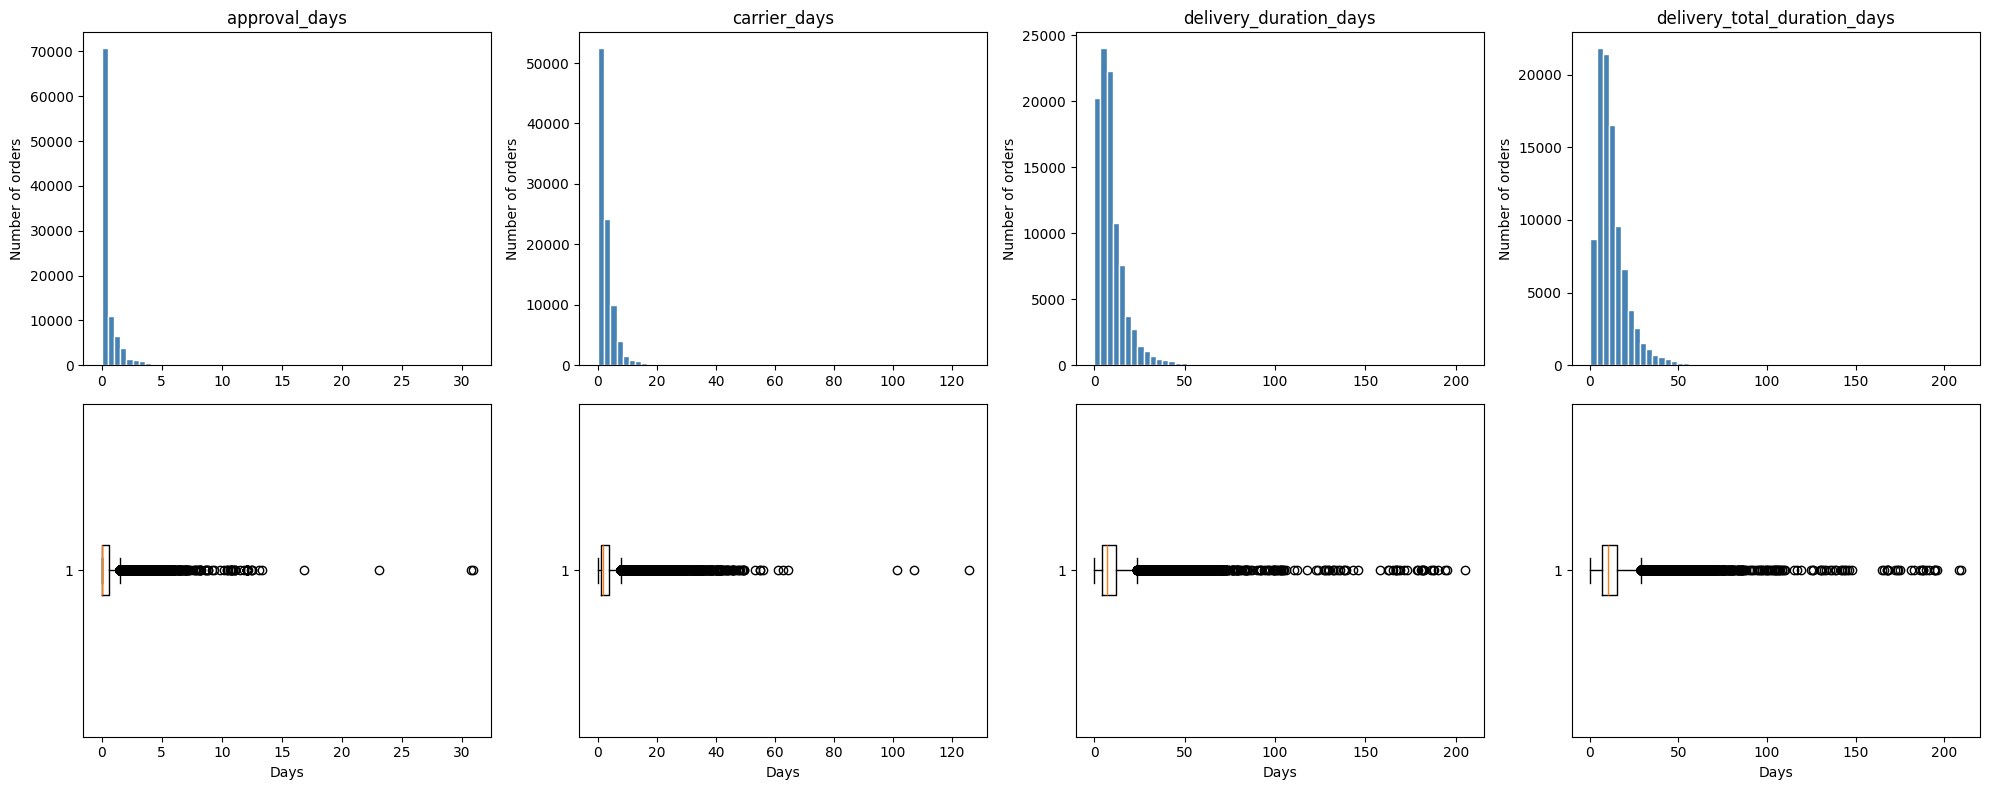

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,flag_approved_before_purchase,flag_carrier_before_approval,flag_delivered_before_carrier,approval_days,carrier_days,delivery_duration_days,delivery_total_duration_days
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,5,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,False,False,0.007431,2.366493,6.062650,8.436574
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,5,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False,False,False,1.279745,0.462882,12.039410,13.782037
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,5,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,False,False,False,0.011505,0.204595,9.178113,9.394213
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,5,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,False,False,False,0.012419,3.745833,9.450498,13.208750
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,5,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,False,False,False,0.042940,0.893113,1.937824,2.873877
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,5,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,False,False,False,0.000000,1.058310,7.159699,8.218009
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,5,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,False,False,False,0.008090,1.425058,20.760579,22.193727
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,5,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,False,False,False,0.012188,1.241782,23.605451,24.859421
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,5,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,False,False,False,0.005486,3.749097,13.331840,17.086424


In [92]:
feature_cols = ["approval_days", "carrier_days", "delivery_duration_days", "delivery_total_duration_days"]

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for i, col in enumerate(feature_cols):
    values = orders.loc[orders[col] >= 0, col]  # skip the -1 placeholders
    axes[0, i].hist(values, bins=60, color="steelblue", edgecolor="white")
    axes[0, i].set_title(col)
    axes[0, i].set_ylabel("Number of orders")
    axes[1, i].boxplot(values, vert=False)
    axes[1, i].set_xlabel("Days")
    print(f"{col}: n={len(values)}, mean={values.mean():.2f}, median={values.median():.2f}, max={values.max():.2f}")
plt.tight_layout()
plt.show()
orders


### 3.2 Outliers: IQR rule

In [98]:
cols = ["approval_days", "carrier_days", "delivery_duration_days", "delivery_total_duration_days"]

report_rows = []
flag_any = pd.Series(False, index=orders.index)

for col in cols:
    placeholder = orders[col] == -1                      # undelivered orders
    negative_errors = (orders[col] <-1)                  # impossible values, data errors
    valid = orders[col] >= 0                             # real values only
    logv = np.log1p(orders.loc[valid, col])

    q1, q3 = logv.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr

    flag = pd.Series(False, index=orders.index)
    flag.loc[logv.index] = ~logv.between(lo, hi)
    orders[f"flag_outlier_{col}"] = flag
    flag_any |= flag

    outliers = orders.loc[flag, col]
    report_rows.append({
        "column": col,
        #"placeholder_(-1)": int(placeholder.sum()),
        "negative_errors": int(negative_errors.sum()),
        "valid_values": int(valid.sum()),
        "outliers": int(flag.sum()),
        "outlier_pct_%": round(100 * flag.sum() / valid.sum(), 2),
        "normal_range_days": f"[{np.expm1(lo):.2f}, {np.expm1(hi):.2f}]",
        "min_outlier_days": round(outliers.min(), 2) if len(outliers) else None,
        "max_outlier_days": round(outliers.max(), 2) if len(outliers) else None,
        "median_all_days": round(orders.loc[valid, col].median(), 2),
    })

report = pd.DataFrame(report_rows)
print("=== OUTLIER REPORT ===")
print(report.to_string(index=False))

print(f"\nOrders flagged in at least one column: {flag_any.sum()} "
      f"({flag_any.mean():.2%} of all {len(orders)} orders)")

print("\nFlagged orders by order_status:")
print(orders.loc[flag_any, "order_status"].value_counts().sort_index())

print("\nFlagged orders for total duration (largest first):")
print(orders.loc[orders["flag_outlier_delivery_total_duration_days"],
                 ["order_id", "order_status", "delivery_total_duration_days"]]
      .sort_values("delivery_total_duration_days", ascending=False).head(5).to_string(index=False))



=== OUTLIER REPORT ===
                      column  negative_errors  valid_values  outliers  outlier_pct_% normal_range_days  min_outlier_days  max_outlier_days  median_all_days
               approval_days                0         96464      4224           4.38     [-0.50, 2.22]              2.22             30.89             0.01
                carrier_days              453         95112      1048           1.10    [-0.50, 16.50]             16.51            125.76             1.85
      delivery_duration_days               16         96446       410           0.43     [0.25, 52.18]              0.00            205.19             7.10
delivery_total_duration_days                0         96470       994           1.03     [1.46, 51.82]              0.53            209.63            10.22

Orders flagged in at least one column: 6159 (6.19% of all 99441 orders)

Flagged orders by order_status:
order_status
5    6159
Name: count, dtype: int64

Flagged orders for total duration (larges

In [108]:
cols = ["approval_days", "carrier_days", "delivery_duration_days", "delivery_total_duration_days"]

impossible = (orders[cols] < -1).any(axis=1)     # real negative values, not the -1 placeholder
print("Rows with impossible negative values:", impossible.sum())

orders = orders[~impossible].copy()
print("Rows left:", len(orders))

print(orders.shape)
orders

Rows with impossible negative values: 0
Rows left: 98972
(98972, 19)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,flag_approved_before_purchase,flag_carrier_before_approval,flag_delivered_before_carrier,approval_days,carrier_days,delivery_duration_days,delivery_total_duration_days,flag_outlier_approval_days,flag_outlier_carrier_days,flag_outlier_delivery_duration_days,flag_outlier_delivery_total_duration_days
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,5,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,False,False,0.007431,2.366493,6.062650,8.436574,False,False,False,False
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,5,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False,False,False,1.279745,0.462882,12.039410,13.782037,False,False,False,False
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,5,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,False,False,False,0.011505,0.204595,9.178113,9.394213,False,False,False,False
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,5,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,False,False,False,0.012419,3.745833,9.450498,13.208750,False,False,False,False
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,5,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,False,False,False,0.042940,0.893113,1.937824,2.873877,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,5,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28,False,False,False,0.000000,1.058310,7.159699,8.218009,False,False,False,False
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,5,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02,False,False,False,0.008090,1.425058,20.760579,22.193727,False,False,False,False
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,5,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27,False,False,False,0.012188,1.241782,23.605451,24.859421,False,False,False,False
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,5,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,False,False,False,0.005486,3.749097,13.331840,17.086424,False,False,False,False


## 4. Dimensionality reduction

Rows used: 95082


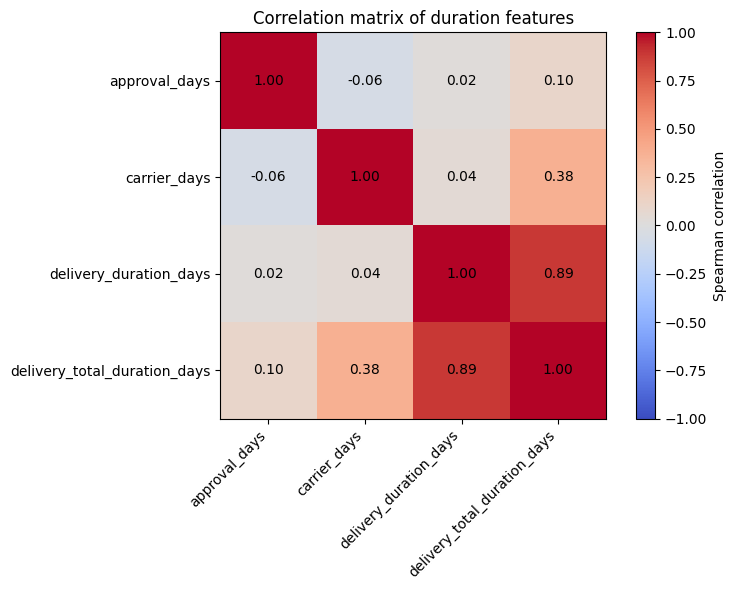

                              approval_days  carrier_days  \
approval_days                         1.000        -0.058   
carrier_days                         -0.058         1.000   
delivery_duration_days                0.022         0.041   
delivery_total_duration_days          0.098         0.380   

                              delivery_duration_days  \
approval_days                                  0.022   
carrier_days                                   0.041   
delivery_duration_days                         1.000   
delivery_total_duration_days                   0.890   

                              delivery_total_duration_days  
approval_days                                        0.098  
carrier_days                                         0.380  
delivery_duration_days                               0.890  
delivery_total_duration_days                         1.000  


In [104]:
# Not applied. The prepared data has only three numeric time features,
# so PCA or a similar method would not reduce anything meaningful here.


feature_cols = ["approval_days", "carrier_days", "delivery_duration_days", "delivery_total_duration_days"]

# Use only rows where all four features are real values (no -1 placeholders, no NaN)
valid = (orders[feature_cols] >= 0).all(axis=1)
corr_df = orders.loc[valid, feature_cols]
print("Rows used:", len(corr_df))

# Spearman handles the skewed durations better than Pearson
corr = corr_df.corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(feature_cols)))
ax.set_xticklabels(feature_cols, rotation=45, ha="right")
ax.set_yticks(range(len(feature_cols)))
ax.set_yticklabels(feature_cols)
for i in range(len(feature_cols)):
    for j in range(len(feature_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", color="black")
fig.colorbar(im, ax=ax, label="Spearman correlation")
ax.set_title("Correlation matrix of duration features")
plt.tight_layout()
plt.show()

print(corr.round(3))


## 5. Save the prepared data

In [103]:
orders.to_csv("prepared_orders.csv", index=False)
print(f"Saved {len(orders)} rows to prepared_orders.csv")

try:
    from google.colab import files
    files.download("prepared_orders.csv")
except ImportError:
    pass  # not running in Colab

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_6176/1531006577.py", line 1, in <cell line: 0>
    orders.to_csv("prepared_orders.csv", index=False)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/pandas/util/_decorators.py", line 333, in wrapper
    return func(*args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/pandas/core/generic.py", line 3967, in to_csv
    return DataFrameRenderer(formatter).to_csv(
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        path_or_buf,
        ^^^^^^^^^^^^
    ...<14 lines>...
        storage_options=storage_options,
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/pandas/io/formats/format.py", line 1014, in to_

TypeError: object of type 'NoneType' has no len()